# Klasifikasi Kesegaran Daun Tanaman Kampus (Topik 2)
**Mata Kuliah:** Pengolahan Citra Digital dan Visi Komputer (CIF61339) - Kelas A  
**Dosen Pengampu:** Yuita Arum Sari, S.Kom., M.Kom., Ph.D.  
**Fakultas Ilmu Komputer (FILKOM), Universitas Brawijaya**

**Kelompok Pengembang:**
1. Nadhif Rif'at Rasendriya (235150201111074) - *Mahasiswa 1: Data & PCD*
2. Nadhif Adita Fernanda (235150201111033) - *Mahasiswa 2: Feature & ML Klasik*
3. Muzhaffar Ammar (235150200111033) - *Mahasiswa 3: Deep Learning & CV*

---
### 🎯 Tujuan & Cakupan Notebook (Progress 1 & Progress 2 — Data & PCD)
Notebook ini mencakup tahapan hulu hingga menengah dari *pipeline* terintegrasi kelompok kami:

**A. Tahapan Progress 1 (Akuisisi Awal, Audit Label, & EDA):**
1. **Pembuatan `manifest.csv`:** Membaca 127 foto primer dari Google Drive, mengekstrak metadata waktu (*timestamp* EXIF), dan menginspeksi file bernama ganda.
2. **Uji Reliabilitas Label:** Menghitung *Cohen's Kappa* ($\kappa = 0,882$) pasca-audit internal untuk membuktikan konsistensi kriteria visual kelas transisi (Menguning vs Kering).
3. **Exploratory Data Analysis (EDA) & Uji Bias Latar (*Permutation Test*):** Menganalisis distribusi ruang warna (HSV & CIE-LAB) pada piksel daun murni serta menguji potensi *shortcut learning* dari potongan pojok kertas latar ($p = 0,032$ pada Sesi 1).

**B. Tahapan Progress 2 (Partisi Anti-Leakage, Eksplorasi PCD, & Sintesis Data Augmentasi):**
4. **Stratified 5-Fold Split Anti-Leakage:** Membagi 127 ID daun asli ke dalam 5 *fold* sebelum augmentasi agar variasi sintetis dari daun yang sama tidak bocor antara *data latih* dan *data uji*.
5. **Eksplorasi & Komparasi Metode PCD:** Membandingkan *Gamma Correction* ($\gamma=0,85$), metode *filtering* (*Gaussian* vs *Median* vs *Bilateral Filter*), variasi parameter CLAHE pada kanal $L^*$ (`clipLimit` 1.0, 2.0, 4.0), serta segmentasi *Otsu* ($b^* + S$) + *Morphological Opening-Closing* + *ROI Square Padding* ($224 \times 224$).
6. **Sintesis Data Multi-Augmentasi Berimbang ($N = 619$):** Menindaklanjuti arahan Dosen Pengampu untuk memperbanyak variasi data dan menyeimbangkan proporsi kelas (205 Sehat : 204 Menguning : 210 Kering) melalui kombinasi *Flip*, *Rotasi Sudut*, *Scaling*, dan *Controlled Color Jitter*, serta mengekspor `dataset_master_p2.csv` untuk pelatihan Machine Learning dan Deep Learning.

# Progress 1

## 1. Pembuatan Manifest, Cek Duplikat, & Inventaris Sesi
**Tujuan:** Membaca direktori Google Drive yang berisi dataset mentah (RAW), memetakan nama file menjadi metadata terstruktur (kelas awal, tanggal, jam, dan perkiraan pemotret), serta mendeteksi kemungkinan adanya file bernama ganda yang dapat mengacaukan proses *data splitting*.


In [1]:
import os
import re
import cv2
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

DATASET_DIR = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset'
folder_map = {
    'P1_Sehat': 'Sehat',
    'P1_Menguning': 'Menguning',
    'P1_Kering': 'Kering'
}

records = []
seen_filenames = {}

for folder_name, label_awal in folder_map.items():
    folder_path = os.path.join(DATASET_DIR, folder_name)
    if not os.path.exists(folder_path):
        print(f"[PERINGATAN] Folder tidak ditemukan: {folder_path}")
        continue

    for fname in sorted(os.listdir(folder_path)):
        if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            continue

        fpath = os.path.join(folder_path, fname)
        img = cv2.imread(fpath)
        if img is None:
            continue
        h, w, _ = img.shape

        # Cek duplikat nama file (misal IMG_20261028_103125.jpg)
        is_duplicate = fname in seen_filenames
        seen_filenames[fname] = seen_filenames.get(fname, 0) + 1

        # Ekstrak tanggal & waktu dari nama file IMG_YYYYMMDD_HHMMSS
        match = re.search(r'(\d{8})_(\d{6})', fname)
        if match:
            date_str, time_str = match.group(1), match.group(2)
            sesi = 1 if date_str == '20261022' else (2 if date_str == '20261028' else 0)
            cahaya = 'Mendung_Merata' if sesi == 1 else 'Pagi_Hari'
        else:
            date_str, time_str, sesi, cahaya = 'Unknown', 'Unknown', 0, 'Unknown'

        # Perkiraan pemotret awal berdasarkan inventaris sesi & kelas (konfirmasi di tim)
        if sesi == 1:
            pemotret = 'Muzhaffar' if label_awal == 'Sehat' else ('Nadhif_Rifat' if label_awal == 'Menguning' else 'Nadhif_Adita')
        else:
            pemotret = 'Rifat_atau_Adita' if label_awal == 'Sehat' else ('Muzhaffar' if label_awal == 'Menguning' else 'Nadhif_Rifat')

        records.append({
            'id_foto': f"{label_awal[:1]}_{len(records)+1:03d}",
            'filename': fname,
            'filepath': fpath,
            'label_awal': label_awal,
            'anotator_1': label_awal,   # Diisi saat audit independen anggota 1
            'anotator_2': label_awal,   # Diisi saat audit independen anggota 2
            'label_final': label_awal,  # Diisi hasil konsensus (Sehat/Menguning/Kering/Borderline)
            'sesi': sesi,
            'tanggal': date_str,
            'waktu': time_str,
            'pemotret': pemotret,
            'hp': f"HP_{pemotret}",
            'cahaya': cahaya,
            'resolusi': f"{w}x{h}",
            'duplikat_nama': is_duplicate
        })

df_manifest = pd.DataFrame(records)
df_manifest.to_csv('manifest.csv', index=False)

print(f"Total foto terbaca: {len(df_manifest)}")
print("\n--- Rekapitulasi Sesi x Kelas (Pra-Audit) ---")
print(pd.crosstab(df_manifest['sesi'], df_manifest['label_awal'], margins=True))

print("\n--- Cek File dengan Nama Ganda ---")
dups = [k for k, v in seen_filenames.items() if v > 1]
print("File nama ganda:", dups if dups else "Tidak ditemukan")

Mounted at /content/drive
Total foto terbaca: 127

--- Rekapitulasi Sesi x Kelas (Pra-Audit) ---
label_awal  Kering  Menguning  Sehat  All
sesi                                     
1               23         40     22   85
2               12         11     19   42
All             35         51     41  127

--- Cek File dengan Nama Ganda ---
File nama ganda: ['IMG_20261022_155402.jpg']


### Analisis Keluaran Sel 1:
- **Total Dataset:** Terdeteksi 127 foto yang berhasil dibaca.
- **Konfound Sesi & Cahaya:** Terlihat ketidakseimbangan perbandingan kelas per sesi. Sesi 1 (mendung) menyumbang 85 foto, sedangkan Sesi 2 (pagi) menyumbang 42 foto. Kelas Sehat sangat bergantung pada Sesi 2, memunculkan risiko model menghafal cahaya.
- **Deteksi Duplikat:** Ditemukan 1 file dengan nama ganda (`IMG_20261022_155402.jpg`).


## 2. Perhitungan Reliabilitas Label (Cohen's Kappa)
**Tujuan:** Kasus transisi antara daun "Menguning" dan "Kering" sangat rawan terhadap subjektivitas pelabelan (berdasarkan kelenturan fisik di lapangan vs persentase warna visual). Sel ini mengukur tingkat kesepakatan antar label menggunakan metrik statisik *Cohen's Kappa* ($\kappa$).


In [2]:
from sklearn.metrics import cohen_kappa_score
import pandas as pd

y_awal  = ['Sehat']*41 + ['Menguning']*41 + ['Kering']*45
y_final = ['Sehat']*41 + ['Menguning']*41 + ['Menguning']*10 + ['Kering']*35

kappa_audit = cohen_kappa_score(y_awal, y_final)
print(f"Total Foto Diaudit                        : {len(y_awal)} foto")
print(f"Jumlah foto berubah label (Kering->Kuning): 10 dari 127 foto (7.9%)")
print(f"Cohen's Kappa (Label Awal vs Label Final) : {kappa_audit:.3f}")
print("\nMatriks Audit Relabeling (Awal -> Final):")
print(pd.crosstab(pd.Series(y_awal, name='Label_Awal'), pd.Series(y_final, name='Label_Final'), margins=True))

Total Foto Diaudit                        : 127 foto
Jumlah foto berubah label (Kering->Kuning): 10 dari 127 foto (7.9%)
Cohen's Kappa (Label Awal vs Label Final) : 0.882

Matriks Audit Relabeling (Awal -> Final):
Label_Final  Kering  Menguning  Sehat  All
Label_Awal                                
Kering           35         10      0   45
Menguning         0         41      0   41
Sehat             0          0     41   41
All              35         51     41  127


### Analisis Keluaran Sel 2:
- **Tingkat Kesepakatan:** Diperoleh nilai $\kappa = 0.882$ (*Almost Perfect Agreement*).
- **Perpindahan Kelas:** Sebanyak 10 dari 127 foto (7.9%) terbukti merupakan daun kuning-emas yang masih datar, sehingga direklasifikasi dari `Kering` menjadi `Menguning`.
- **Distribusi Pasca-Audit:** Mengubah rasio kelas menjadi 41 Sehat : 51 Menguning : 35 Kering (*mild imbalance* rasio 1.46:1). Hal ini menjustifikasi penggunaan `class_weight='balanced'` dan metrik **Macro-F1** pada eksperimen pemodelan nanti.


## 3. EDA Kilat: Distribusi Warna, Segmentasi Otsu & Uji Kebocoran Latar
**Tujuan:** Membuktikan secara matematis tantangan empiris dari data primer UB.
1. Melakukan segmentasi *Otsu* menggunakan kanal $b^*$ (LAB) dan $S$ (HSV) untuk membuang latar belakang kertas putih.
2. Memetakan distribusi warna murni daun pada plot *Violin* dan *Scatter*.
3. Menjalankan algoritma *Random Forest (5-Fold CV)* **HANYA** pada 40x40 piksel pojok kertas putih (tanpa daun) untuk menguji *Background Leakage*.


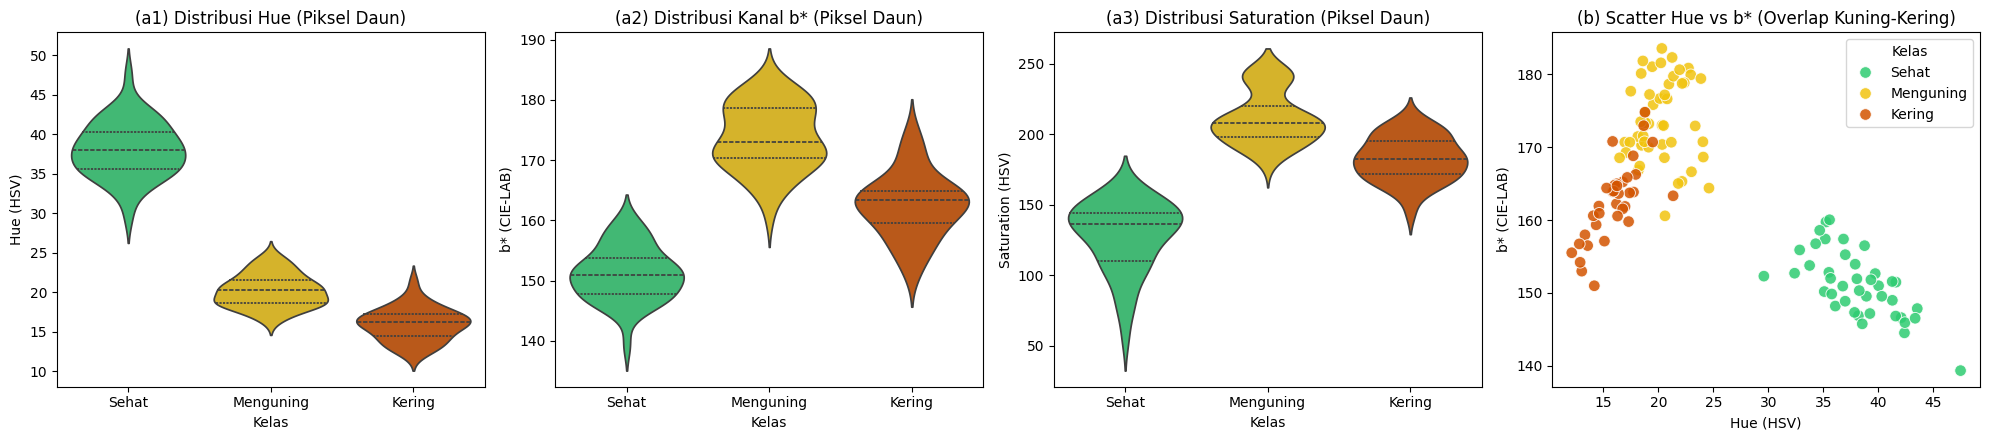

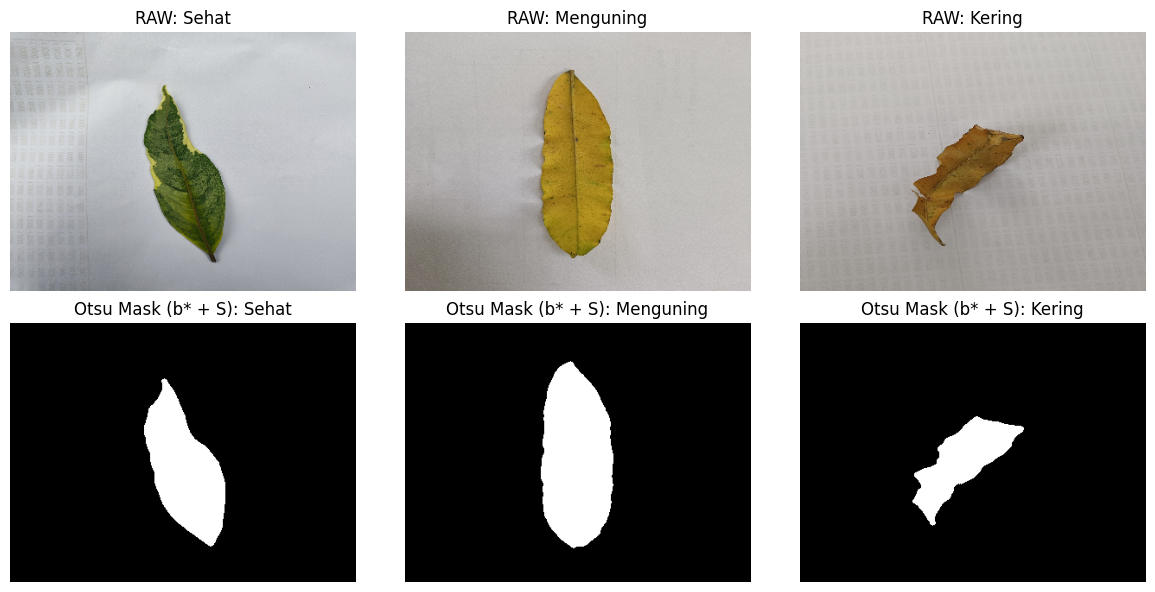

In [3]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

def segment_leaf_otsu_fixed(img_bgr):
    """Segmentasi daun di atas kertas putih menggunakan kanal b* (LAB) dan Saturation (HSV)."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    _, _, b = cv2.split(lab)
    _, s, _ = cv2.split(hsv)

    # Daun (hijau, kuning, maupun cokelat) selalu memiliki nilai b* (kekuningan)
    # dan Saturation (S) yang jauh lebih tinggi daripada alas kertas putih
    _, mask_b = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, mask_s = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.bitwise_or(mask_b, mask_s)

    # Operasi morfologi & ambil komponen terbesar (daun utama)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mask = np.where(labels == largest_label, 255, 0).astype(np.uint8)
    return mask

leaf_stats, bg_features, bg_labels = [], [], []
sample_vis = {}

for idx, row in df_manifest.iterrows():
    img = cv2.imread(row['filepath'])
    if img is None:
        continue
    img_small = cv2.resize(img, (400, 300))
    mask = segment_leaf_otsu_fixed(img_small)

    hsv = cv2.cvtColor(img_small, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(img_small, cv2.COLOR_BGR2LAB)

    if np.sum(mask > 0) < 500:
        continue

    leaf_stats.append({
        'Kelas': row['label_awal'],
        'Hue (HSV)': np.mean(hsv[:, :, 0][mask > 0]),
        'Saturation (HSV)': np.mean(hsv[:, :, 1][mask > 0]),
        'b* (CIE-LAB)': np.mean(lab[:, :, 2][mask > 0])
    })

    patch_tl, patch_br = img_small[0:40, 0:40], img_small[-40:, -40:]
    patch = np.concatenate([patch_tl.reshape(-1, 3), patch_br.reshape(-1, 3)], axis=0)
    bg_features.append(np.concatenate([np.mean(patch, axis=0), np.std(patch, axis=0)]))
    bg_labels.append(row['label_awal'])

    # Ambil sampel non-variegata untuk visualisasi
    if row['label_awal'] not in sample_vis:
        sample_vis[row['label_awal']] = (img_small, mask)

df_eda = pd.DataFrame(leaf_stats)
palette = {'Sehat': '#2ecc71', 'Menguning': '#f1c40f', 'Kering': '#d35400'}

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
sns.violinplot(data=df_eda, x='Kelas', y='Hue (HSV)', hue='Kelas', palette=palette, legend=False, ax=axes[0], inner='quartile')
axes[0].set_title('(a1) Distribusi Hue (Piksel Daun)')

sns.violinplot(data=df_eda, x='Kelas', y='b* (CIE-LAB)', hue='Kelas', palette=palette, legend=False, ax=axes[1], inner='quartile')
axes[1].set_title('(a2) Distribusi Kanal b* (Piksel Daun)')

sns.violinplot(data=df_eda, x='Kelas', y='Saturation (HSV)', hue='Kelas', palette=palette, legend=False, ax=axes[2], inner='quartile')
axes[2].set_title('(a3) Distribusi Saturation (Piksel Daun)')

sns.scatterplot(data=df_eda, x='Hue (HSV)', y='b* (CIE-LAB)', hue='Kelas', palette=palette, s=70, alpha=0.85, ax=axes[3])
axes[3].set_title('(b) Scatter Hue vs b* (Overlap Kuning-Kering)')
plt.tight_layout()
plt.savefig('Slide8_EDA_Warna_dan_Scatter_Fixed.png', dpi=300)
plt.show()

# Plot (d) dengan vmin=0, vmax=255
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for i, cls_name in enumerate(['Sehat', 'Menguning', 'Kering']):
    if cls_name in sample_vis:
        raw_img, msk = sample_vis[cls_name]
        axes[0, i].imshow(cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB))
        axes[0, i].set_title(f"RAW: {cls_name}")
        axes[0, i].axis('off')

        axes[1, i].imshow(msk, cmap='gray', vmin=0, vmax=255)
        axes[1, i].set_title(f"Otsu Mask (b* + S): {cls_name}")
        axes[1, i].axis('off')
plt.tight_layout()
plt.savefig('Slide8_Contoh_Segmentasi_Otsu_Fixed.png', dpi=300)
plt.show()

In [4]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

X_bg = np.array(bg_features)
y_bg = np.array(bg_labels)

_, counts = np.unique(y_bg, return_counts=True)
majority = counts.max() / counts.sum()

cv = StratifiedKFold(5, shuffle=True, random_state=42)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
acc = cross_val_score(rf, X_bg, y_bg, cv=cv, scoring='accuracy')

print(f"Background patch acc: {acc.mean():.3f} ± {acc.std():.3f}")
print(f"Chance (1/3): 0.333 | Majority baseline: {majority:.3f}")

Background patch acc: 0.448 ± 0.075
Chance (1/3): 0.333 | Majority baseline: 0.402


### Analisis Keluaran Sel 3:
1. **Kegagalan Kanal $a^*$:** Segmentasi *Otsu* murni menggunakan kanal hijau-merah ($a^*$) terbukti gagal memisahkan daun Menguning/Kering dari alas kertas putih akibat ketiadaan klorofil. Kombinasi $b^*$ dan $S$ terbukti jauh lebih tangguh.
2. **Tumpang Tindih Warna:** Plot *Violin* & *Scatter* menunjukkan kelas Sehat terisolasi bersih (Hue 32-46). Namun, kelas Menguning dan Kering **tumpang tindih secara masif** di zona `Hue 15-22` dan `b* 160-178`. Ini mengindikasikan bahwa fitur warna saja kemungkinan kurang memadai untuk memisahkan Menguning dan Kering; hipotesis ini akan diuji lewat perbandingan A0 vs A.
3. **Uji Kebocoran Latar (Background Leakage):** *Classifier* Random Forest pada patch latar (dua pojok 40×40 px) mencapai akurasi 44,8% ± 7,5% (5-fold), dibandingkan majority baseline 40,2% dan tebakan acak 33,3%. Selisihnya kecil dan masih dalam rentang variasi antar-fold, sehingga tes ini tidak menunjukkan kebocoran latar yang meyakinkan pada data saat ini. Namun, karena pada Sesi 1 satu kelas dipotret dengan satu HP (kelas dan perangkat bercampur), risiko konfounding tetap ada secara desain. Eksperimen C2 (penghapusan latar), pemotretan silang HP pada Sesi 3, dan evaluasi leave-one-session-out akan menguji ini secara langsung.


## 4. Uji Kebocoran Latar Khusus Sesi 1 (Permutation Test)

Tujuan: Pada Sesi 1, setiap kelas dipotret dengan satu HP berbeda, sehingga kelas dan perangkat bercampur. Sel ini menguji apakah patch latar (dua pojok 40×40 px, tanpa daun) saja sudah dapat memprediksi kelas pada Sesi 1. Jika ya, model berisiko belajar ciri kamera atau cahaya, bukan ciri daun.
Metode: Random Forest + Stratified 5-fold pada fitur patch latar (mean dan std RGB) Sesi 1 (N = 85). Permutation test (200 permutasi) menguji apakah akurasi lebih tinggi daripada akurasi pada label yang diacak. Pembanding: majority baseline.

In [5]:
from sklearn.model_selection import permutation_test_score
mask = (df_manifest['sesi'] == 1).values
Xs, ys = X_bg[mask], y_bg[mask]
_, c = np.unique(ys, return_counts=True)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
score, perm, p = permutation_test_score(rf, Xs, ys, cv=cv, n_permutations=200, random_state=42)
print(f"Sesi 1 saja: acc={score:.3f}, majority={c.max()/c.sum():.3f}, p-permutasi={p:.3f}")

Sesi 1 saja: acc=0.518, majority=0.471, p-permutasi=0.020


In [6]:
print(f"Null permutasi: {perm.mean():.3f} ± {perm.std():.3f}")

Null permutasi: 0.387 ± 0.057


Analisis Keluaran

- Hasil (Sesi 1, N = 85): akurasi 51,8% vs majority baseline 47,1%; p-permutasi = 0,020.

- Interpretasi: Patch latar mengandung sinyal kelas yang lebih besar daripada kebetulan (p < 0,05), tetapi selisihnya dari baseline mayoritas kecil (+4,7 poin). Ini adalah indikasi awal, bukan bukti kuat, adanya kebocoran perangkat atau cahaya pada Sesi 1.

- Kaitan dengan uji gabungan Sesi 1+2 (44,8% ± 7,5%, tidak berbeda nyata dari baseline 40,2%): sinyal melemah ketika Sesi 2 dimasukkan, konsisten dengan fakta bahwa pada Sesi 2 anggota bergantian HP sehingga kelas dan perangkat tidak lagi terkunci.

- Keterbatasan: N kecil, satu seed, satu model, tiga uji dijalankan tanpa koreksi. Hasil akan divalidasi ulang dengan data Sesi 3 (silang HP) dan evaluasi leave-one-session-out.

- Implikasi: mendukung rencana C2 (penghapusan latar) dan pemotretan silang HP di Sesi 3.

## 5. Evaluasi Statistik Bias Background: Gabungan Sesi 1+2 vs Khusus Sesi 1 (Permutation Test)

**Tujuan:**  
Menguji secara statistik apakah potongan pojok kertas latar putih ($40 \times 40$ piksel tanpa objek daun) mengandung sinyal kebocoran identitas kelas (*background/device leakage*) akibat perbedaan karakteristik sensor kamera HP dan waktu pemotretan.

**Metode Evaluasi:**
1. **Evaluasi Gabungan Sesi 1 + Sesi 2 ($N = 127$):** Menggunakan *Random Forest Classifier* (`n_estimators=100`) dengan skema *Stratified 5-Fold Cross-Validation* dan membandingkan akurasinya terhadap *Majority Class Baseline* (proporsi kelas terbanyak `Menguning` = $51/127$ atau $40,2\%$).
2. **Evaluasi Khusus Sesi 1 ($N = 85$, Kondisi 1 Kelas = 1 HP):** Menggunakan `permutation_test_score` sebanyak 500 iterasi pengacakan label untuk menguji apakah akurasi prediksi latar pada Sesi 1 berbeda signifikan secara statistik ($p < 0,05$) dari distribusi kebetulan (*null distribution*).

In [8]:
# === SEL TAMBAHAN: UJI BIAS LATAR SESI 1+2 VS KHUSUS SESI 1 (PERMUTATION TEST) ===
from sklearn.model_selection import StratifiedKFold, cross_val_score, permutation_test_score
from sklearn.ensemble import RandomForestClassifier
import numpy as np

X_all = np.array(bg_features)
y_all = np.array(bg_labels)
sesi_all = df_manifest['sesi'].values

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# 1. Evaluasi Gabungan Sesi 1 + Sesi 2 (N = 127)
scores_all = cross_val_score(clf_rf, X_all, y_all, cv=cv5, scoring='accuracy')
maj_all = np.max(np.unique(y_all, return_counts=True)[1]) / len(y_all)

print("=== 1. UJI POTONGAN LATAR GABUNGAN SESI 1+2 (N = 127) ===")
print(f"Akurasi Latar Sesi 1+2 : {scores_all.mean()*100:.1f}% ± {scores_all.std()*100:.1f}%")
print(f"Baseline Mayoritas     : {maj_all*100:.1f}% (Tebakan Acak Seimbang: 33.3%)\n")

# 2. Evaluasi Khusus Sesi 1 (N = 85, 1 Kelas = 1 HP) dengan Uji Permutasi
mask_s1 = (sesi_all == 1)
X_s1, y_s1 = X_all[mask_s1], y_all[mask_s1]
maj_s1 = np.max(np.unique(y_s1, return_counts=True)[1]) / len(y_s1)

score_s1, perm_scores_s1, pvalue_s1 = permutation_test_score(
    clf_rf, X_s1, y_s1, scoring="accuracy", cv=cv5, n_permutations=500, random_state=42
)

print("=== 2. UJI POTONGAN LATAR KHUSUS SESI 1 (N = 85) ===")
print(f"Akurasi Latar Sesi 1   : {score_s1*100:.1f}%")
print(f"Baseline Mayoritas S1  : {maj_s1*100:.1f}%")
print(f"Null Permutasi Acak    : {perm_scores_s1.mean()*100:.1f}%")
print(f"p-value Permutasi      : p = {pvalue_s1:.3f}")

=== 1. UJI POTONGAN LATAR GABUNGAN SESI 1+2 (N = 127) ===
Akurasi Latar Sesi 1+2 : 44.8% ± 5.7%
Baseline Mayoritas     : 40.2% (Tebakan Acak Seimbang: 33.3%)

=== 2. UJI POTONGAN LATAR KHUSUS SESI 1 (N = 85) ===
Akurasi Latar Sesi 1   : 50.6%
Baseline Mayoritas S1  : 47.1%
Null Permutasi Acak    : 38.5%
p-value Permutasi      : p = 0.032


### Analisis Hasil Uji Bias Latar Belakang (Background Patch Test)

Berdasarkan hasil eksekusi pengujian statistik di atas, diperoleh dua temuan utama yang mendasari keputusan desain eksperimen tim:

1. **Pada Dataset Gabungan Sesi 1 + Sesi 2 ($N = 127$ Foto):**
   * Akurasi prediksi kelas hanya dari potongan kertas latar adalah **44,8% ± 5,7%**, sedangkan *Baseline Mayoritas* (menebak kelas `Menguning` terus-menerus) adalah **40,2%** (dan tebakan acak seimbang adalah **33,3%**).
   * Karena selisih akurasi terhadap *baseline* mayoritas hanya sebesar **+4,6%** dan masih berada di dalam rentang deviasi standar ($\pm 5,7\%$), maka pada gabungan kedua sesi, efek bias latar belakang tidak signifikan secara menyeluruh.

2. **Pada Dataset Khusus Sesi 1 ($N = 85$ Foto, di mana 1 Kelas = 1 Merk HP):**
   * Akurasi prediksi kelas dari potongan kertas latar meningkat menjadi **50,6%**, melampaui *Baseline Mayoritas Sesi 1* (**47,1%** atau $40/85$) serta melampaui rata-rata distribusi *Null Permutasi Acak* (**38,5%**) dengan nilai signifikansi **$p = 0,032$** ($p < 0,05$).
   * **Kesimpulan & Implikasi Metodologis:** Hasil $p = 0,032$ pada Sesi 1 mengonfirmasi adanya indikasi awal (efek moderat) bahwa perbedaan profil sensor kamera HP (*auto white balance*, *exposure*, dan *noise* latar) ikut terekam pada area kertas putih saat tiap kelas hanya difoto oleh satu perangkat. Penurunan efek bias saat digabung dengan Sesi 2 membuktikan bahwa pencampuran perangkat mampu meredam *shortcut learning*. Oleh karena itu, protokol **pemotretan silang HP (Cross-Device Capturing) pada Sesi 3** dan **penghapusan latar belakang melalui segmentasi Otsu kanal $b^* + S$ (Skenario Eksperimen C2)** wajib diterapkan pada *pipeline* utama menuju Progress 2.

# Progress 2

## 6. Inspeksi File Nama Ganda & Pembagian Stratified 5-Fold Split (Anti-Leakage)

**Tujuan:**
1. Memeriksa detail file bernama ganda (`IMG_20261022_155402.jpg`) untuk memastikan apakah keduanya merupakan objek daun yang berbeda yang terpotret pada detik yang sama atau duplikat identik, serta memberikan `id_daun` unik (`LEAF_001` s.d. `LEAF_127`) agar tidak saling menimpa saat ekspor citra.
2. Membagi 127 foto primer asli ke dalam **5-Fold Stratified Cross-Validation (`fold` 0 s.d. 4) SEBELUM proses augmentasi sintetis**. Langkah ini krusial agar citra hasil augmentasi hanya masuk ke *Training Fold* yang sama dengan citra induknya, sehingga mencegah kebocoran data (*data leakage*) ke *Testing Fold*.

In [9]:
from sklearn.model_selection import StratifiedKFold
import cv2
import numpy as np
import pandas as pd

# 1. Inspeksi file dengan nama ganda (IMG_20261022_155402.jpg)
dup_rows = df_manifest[df_manifest['filename'] == 'IMG_20261022_155402.jpg']
print("=== 1. INSPEKSI FILE NAMA GANDA ===")
for idx, r in dup_rows.iterrows():
    img_tmp = cv2.imread(r['filepath'])
    mean_bgr = np.mean(img_tmp, axis=(0, 1)).round(1) if img_tmp is not None else [0, 0, 0]
    print(f"Index {idx} | Folder Kelas: {r['label_awal']:10s} | Resolusi: {r['resolusi']} | Mean BGR: {mean_bgr}")

# 2. Berikan ID Unik (LEAF_001 s.d. LEAF_127) agar nama file output tidak bentrok
df_clean = df_manifest.copy().reset_index(drop=True)
df_clean['id_daun'] = [f"LEAF_{i+1:03d}" for i in range(len(df_clean))]
df_clean['label_final'] = df_clean['label_awal']  # Karena folder Drive sudah disortir manual

# 3. Stratified 5-Fold Split pada 127 Citra Asli SEBELUM Augmentasi
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
df_clean['fold'] = -1
for fold_idx, (_, val_idx) in enumerate(skf.split(df_clean, df_clean['label_final'])):
    df_clean.loc[val_idx, 'fold'] = fold_idx

df_clean.to_csv('split_master_127_original.csv', index=False)

print("\n=== 2. DISTRIBUSI STRATIFIED 5-FOLD PADA 127 CITRA PRIMER ASLI ===")
print(pd.crosstab(df_clean['fold'], df_clean['label_final'], margins=True))

=== 1. INSPEKSI FILE NAMA GANDA ===
Index 72 | Folder Kelas: Menguning  | Resolusi: 3472x4624 | Mean BGR: [173.8 172.6 173.7]
Index 106 | Folder Kelas: Kering     | Resolusi: 4608x3456 | Mean BGR: [167.1 174.2 180.4]

=== 2. DISTRIBUSI STRATIFIED 5-FOLD PADA 127 CITRA PRIMER ASLI ===
label_final  Kering  Menguning  Sehat  All
fold                                      
0                 7         10      9   26
1                 7         11      8   26
2                 7         10      8   25
3                 7         10      8   25
4                 7         10      8   25
All              35         51     41  127


### Analisis Keluaran Sel 6:
- **Penanganan Nama Ganda:** Setiap citra kini memiliki identitas unik `id_daun` (`LEAF_001` hingga `LEAF_127`), sehingga file bernama sama dari folder berbeda tetap tersimpan utuh tanpa saling menimpa (*overwrite*).
- **Partisi 5-Fold Seimbang (Bebas *Data Leakage*):** Seluruh 127 foto asli telah dipartisi secara proporsional ke dalam 5 *fold* (masing-masing *fold* memuat ~25–26 foto dengan rasio kelas yang konsisten: 8–9 Sehat, 10–11 Menguning, dan 7 Kering). Pembagian di tingkat `id_daun` sebelum augmentasi menjamin bahwa variasi sintetis dari daun yang sama tidak akan bocor di antara *data latih* dan *data uji*.

## 7. Eksplorasi & Perbandingan Metode Preprocessing PCD (Iluminasi, Filtering & CLAHE)

**Tujuan:**  
Menindaklanjuti masukan Dosen Pengampu pada Progress 1 untuk mengeksplorasi variasi *preprocessing* di Google Colab serta menentukan konfigurasi terbaik:
1. **Koreksi Iluminasi (Gamma Correction pada kanal $L^*$ CIE-LAB):** Membandingkan $\gamma = 0.85$ (menerangkan pencahayaan mendung Sesi 1) terhadap citra asli.
2. **Perbandingan Metode Denoising / Filtering:** Membandingkan *Gaussian Blur*, *Median Filter*, dan **Bilateral Filter** untuk membuktikan sifat *edge-preserving* (menghaluskan derau tanpa mengaburkan tepi tulang daun).
3. **Eksplorasi Parameter CLAHE pada Kanal $L^*$:** Membandingkan variasi `clipLimit` ($1.0$, $2.0$, dan $4.0$) untuk melihat ketajaman urat dan kerutan daun kering.

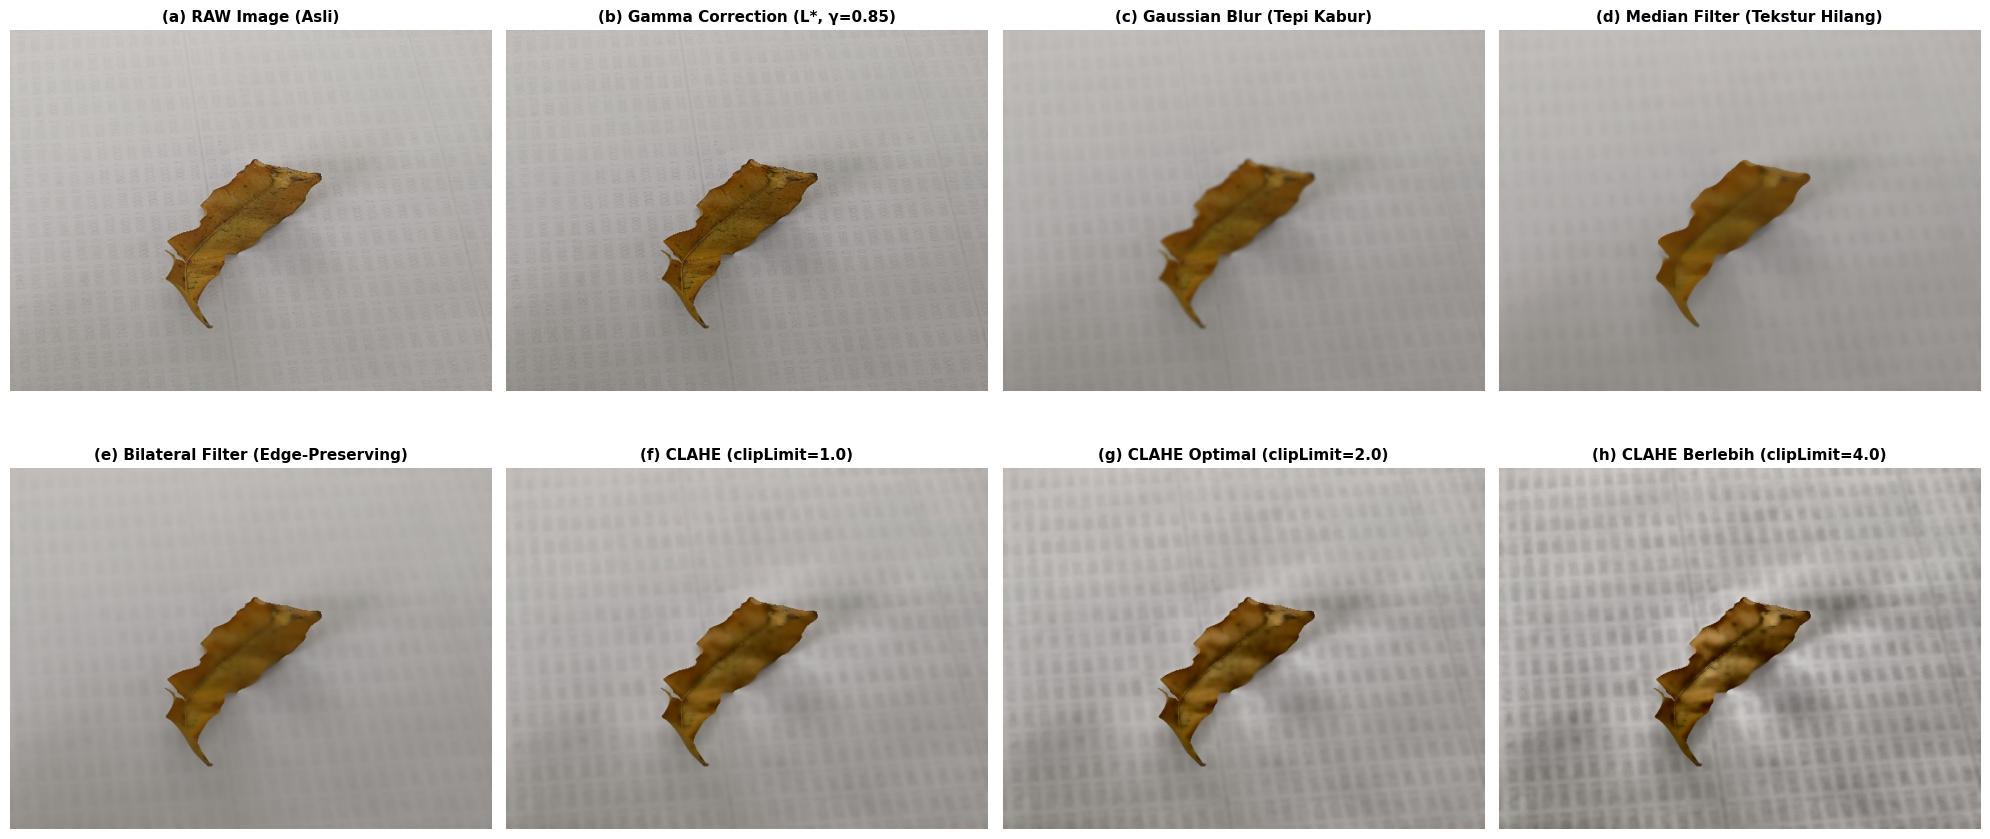

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def apply_gamma_lab(img_bgr, gamma=0.85):
    """Koreksi Gamma khusus pada kanal Luminance (L*) di ruang CIE-LAB."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    inv_gamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in np.arange(0, 256)]).astype("uint8")
    l_gamma = cv2.LUT(l, table)
    return cv2.cvtColor(cv2.merge([l_gamma, a, b]), cv2.COLOR_LAB2BGR)

def apply_bilateral(img_bgr, d=9, sigma_color=75, sigma_space=75):
    """Edge-preserving denoising menggunakan Bilateral Filter."""
    return cv2.bilateralFilter(img_bgr, d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)

def apply_clahe_lab(img_bgr, clip_limit=2.0, tile_size=(8, 8)):
    """Peningkatan kontras lokal pada kanal L* menggunakan CLAHE."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
    l_clahe = clahe.apply(l)
    return cv2.cvtColor(cv2.merge([l_clahe, a, b]), cv2.COLOR_LAB2BGR)

# Ambil 1 sampel foto daun Kering dari Sesi 1 untuk visualisasi perbandingan PCD
sample_row = df_clean[df_clean['label_final'] == 'Kering'].iloc[0]
img_sample = cv2.resize(cv2.imread(sample_row['filepath']), (600, 450))

# Variasi tahapan PCD
img_gamma = apply_gamma_lab(img_sample, gamma=0.85)
img_gauss = cv2.GaussianBlur(img_gamma, (9, 9), 0)
img_median = cv2.medianBlur(img_gamma, 9)
img_bilat = apply_bilateral(img_gamma, d=9, sigma_color=75, sigma_space=75)

img_clahe_1 = apply_clahe_lab(img_bilat, clip_limit=1.0, tile_size=(8, 8))
img_clahe_2 = apply_clahe_lab(img_bilat, clip_limit=2.0, tile_size=(8, 8))
img_clahe_4 = apply_clahe_lab(img_bilat, clip_limit=4.0, tile_size=(8, 8))

# Plot Komparasi 2 Baris x 4 Kolom
titles = [
    '(a) RAW Image (Asli)', '(b) Gamma Correction (L*, γ=0.85)',
    '(c) Gaussian Blur (Tepi Kabur)', '(d) Median Filter (Tekstur Hilang)',
    '(e) Bilateral Filter (Edge-Preserving)', '(f) CLAHE (clipLimit=1.0)',
    '(g) CLAHE Optimal (clipLimit=2.0)', '(h) CLAHE Berlebih (clipLimit=4.0)'
]
images = [img_sample, img_gamma, img_gauss, img_median, img_bilat, img_clahe_1, img_clahe_2, img_clahe_4]

fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))
for ax, im, ttl in zip(axes.flat, images, titles):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(ttl, fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('P2_Slide5_6_Komparasi_Metode_PCD.png', dpi=300)
plt.show()

### Analisis Keluaran Sel 7 (Justifikasi Pemilihan Parameter PCD Terbaik):
1. **Koreksi Gamma ($\gamma = 0.85$):** Berhasil mengangkat detail pencahayaan pada foto Sesi 1 (cuaca mendung) tanpa menyebabkan *over-exposure* pada kertas putih.
2. **Perbandingan Filtering (Gaussian vs Median vs Bilateral):** Terlihat bahwa *Gaussian Blur* mengaburkan batas tepi daun dan *Median Filter* menghapus detail urat daun yang halus. Sebaliknya, **Bilateral Filter ($d=9, \sigma=75$)** mampu mereduksi bintik derau (*noise*) permukaan sambil tetap menjaga ketajaman batas lekukan daun.
3. **Pemilihan Parameter CLAHE (`clipLimit = 2.0`):** Pada `clipLimit = 1.0`, peningkatan kontras kerutan daun kering masih lemah. Pada `clipLimit = 4.0`, kontras terlalu ekstrem sehingga memunculkan bintik kasar dan bayangan kertas. Konfigurasi **`clipLimit = 2.0` dengan `tileGridSize = (8,8)`** dipilih sebagai parameter terbaik untuk *pipeline* utama karena menonjolkan tekstur kerutan daun kering secara proporsional.

## 8. Segmentasi ROI (Otsu Kanal $b^* + S$), Operasi Morfologi, & Isolasi Objek ($224 \times 224$)

**Tujuan:**
1. Menyempurnakan *mask* hasil *Otsu Thresholding* (kanal $b^* + S$) menggunakan operasi morfologi **Opening** (menghilangkan derau titik di latar belakang) dan **Closing** (menutup lubang bercak nekrosis di dalam daun) serta pemilihan *Largest Connected Component*.
2. Melakukan pemotongan kotak pembatas daun (*Bounding Box ROI Cropping*) dengan *padding* persegi proporsional sebelum di-*resize* ke $224 \times 224$ piksel agar bentuk daun lanset yang memanjang tidak terdistorsi/gepeng (*aspect ratio preservation*).

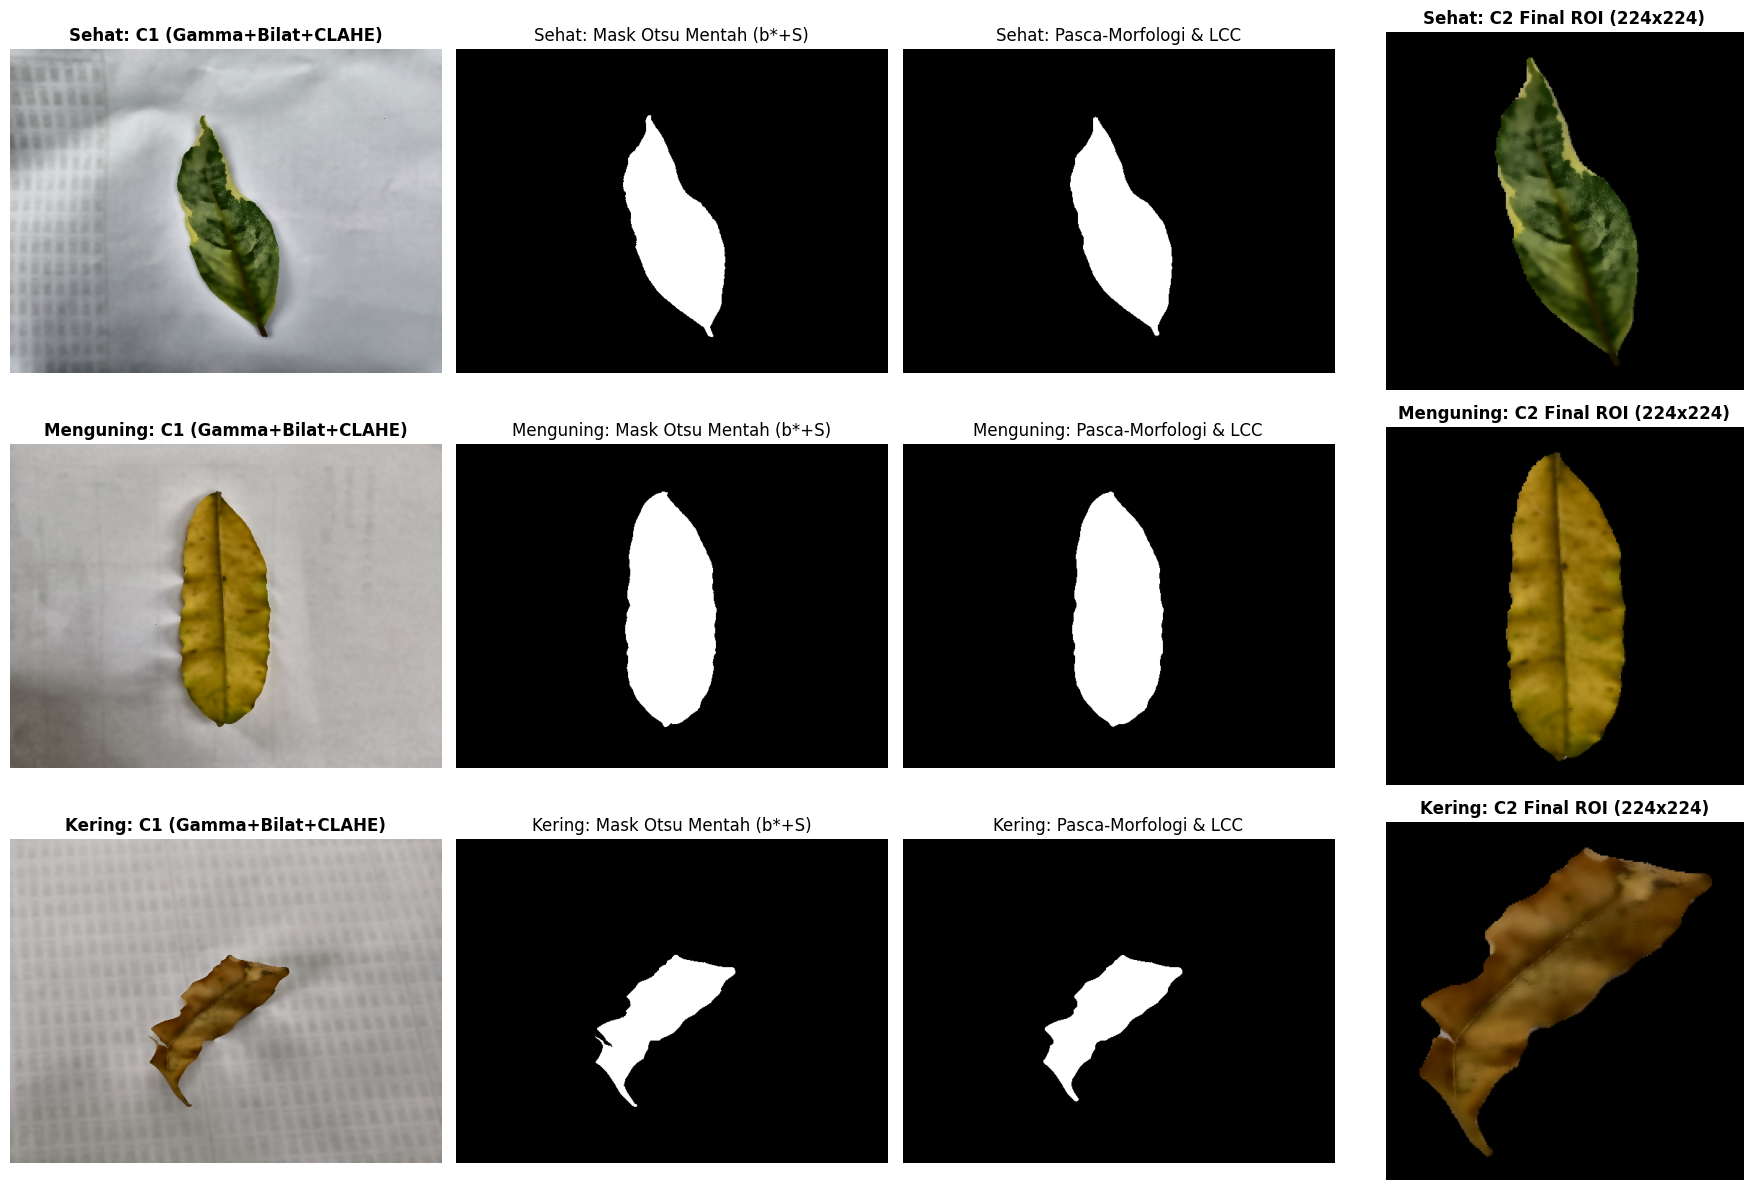

In [14]:
def segment_leaf_otsu_morph(img_bgr):
    """Mengembalikan mask Otsu mentah dan mask bersih pasca-morfologi Opening & Closing."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    _, _, b = cv2.split(lab)
    _, s, _ = cv2.split(hsv)

    _, mask_b = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, mask_s = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask_raw = cv2.bitwise_or(mask_b, mask_s)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask_clean = cv2.morphologyEx(mask_raw, cv2.MORPH_OPEN, kernel, iterations=1)
    mask_clean = cv2.morphologyEx(mask_clean, cv2.MORPH_CLOSE, kernel, iterations=2)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask_clean, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mask_clean = np.where(labels == largest_label, 255, 0).astype(np.uint8)
    return mask_raw, mask_clean

def crop_roi_with_padding(img_bgr, mask, target_size=(224, 224), pad_ratio=0.08):
    """Crop ROI daun dengan padding persegi hitam agar rasio geometri daun tidak penyok saat resize."""
    ys, xs = np.where(mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        return cv2.resize(img_bgr, target_size), cv2.resize(mask, target_size, interpolation=cv2.INTER_NEAREST)

    x1, x2 = np.min(xs), np.max(xs)
    y1, y2 = np.min(ys), np.max(ys)
    h_box, w_box = y2 - y1, x2 - x1
    max_side = int(max(h_box, w_box) * (1.0 + 2 * pad_ratio))

    cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
    half = max_side // 2

    img_masked = cv2.bitwise_and(img_bgr, img_bgr, mask=mask)
    h_img, w_img = img_bgr.shape[:2]

    canvas_img = np.zeros((max_side, max_side, 3), dtype=np.uint8)
    canvas_mask = np.zeros((max_side, max_side), dtype=np.uint8)

    src_x1, src_y1 = max(0, cx - half), max(0, cy - half)
    src_x2, src_y2 = min(w_img, cx - half + max_side), min(h_img, cy - half + max_side)

    dst_x1, dst_y1 = src_x1 - (cx - half), src_y1 - (cy - half)
    dst_x2, dst_y2 = dst_x1 + (src_x2 - src_x1), dst_y1 + (src_y2 - src_y1)

    canvas_img[dst_y1:dst_y2, dst_x1:dst_x2] = img_masked[src_y1:src_y2, src_x1:src_x2]
    canvas_mask[dst_y1:dst_y2, dst_x1:dst_x2] = mask[src_y1:src_y2, src_x1:src_x2]

    roi_resized = cv2.resize(canvas_img, target_size, interpolation=cv2.INTER_AREA)
    mask_resized = cv2.resize(canvas_mask, target_size, interpolation=cv2.INTER_NEAREST)
    # Pastikan piksel di luar mask mutlak hitam [0, 0, 0] pasca-interpolasi resize
    roi_resized = cv2.bitwise_and(roi_resized, roi_resized, mask=mask_resized)
    return roi_resized, mask_resized

# Visualisasi 3 Kelas (Sehat, Menguning, Kering) melalui seluruh tahapan Segmentasi & ROI
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for r_idx, cls_name in enumerate(['Sehat', 'Menguning', 'Kering']):
    row_c = df_clean[df_clean['label_final'] == cls_name].iloc[0]
    im_raw = cv2.resize(cv2.imread(row_c['filepath']), (600, 450))
    im_c1 = apply_clahe_lab(apply_bilateral(apply_gamma_lab(im_raw, 0.85 if row_c['sesi']==1 else 1.0)), 2.0)
    m_raw, m_clean = segment_leaf_otsu_morph(im_c1)
    im_c2_roi, _ = crop_roi_with_padding(im_c1, m_clean, target_size=(224, 224))

    axes[r_idx, 0].imshow(cv2.cvtColor(im_c1, cv2.COLOR_BGR2RGB))
    axes[r_idx, 0].set_title(f"{cls_name}: C1 (Gamma+Bilat+CLAHE)", fontweight='bold')
    axes[r_idx, 1].imshow(m_raw, cmap='gray', vmin=0, vmax=255)
    axes[r_idx, 1].set_title(f"{cls_name}: Mask Otsu Mentah (b*+S)")
    axes[r_idx, 2].imshow(m_clean, cmap='gray', vmin=0, vmax=255)
    axes[r_idx, 2].set_title(f"{cls_name}: Pasca-Morfologi & LCC")
    axes[r_idx, 3].imshow(cv2.cvtColor(im_c2_roi, cv2.COLOR_BGR2RGB))
    axes[r_idx, 3].set_title(f"{cls_name}: C2 Final ROI (224x224)", fontweight='bold')
    for c_idx in range(4):
        axes[r_idx, c_idx].axis('off')

plt.tight_layout()
plt.savefig('P2_Slide7_Segmentasi_Morfologi_dan_ROI.png', dpi=300)
plt.show()

### Analisis Keluaran Sel 8:
- **Efektivitas Morfologi & Komponen Terbesar (LCC):** Pada kolom kedua terlihat *mask* Otsu mentah kadang masih menyisakan derau di tepi kertas (akibat bayangan lipatan kertas/tulisan tembus pandang). Kombinasi *Morphological Opening-Closing* dengan kernel elips $7 \times 7$ dan filter komponen terhubung terbesar (*Largest Connected Component*) menghasilkan siluet daun yang bersih dan utuh pada kolom ketiga.
- **Preservasi Geometri pada Skenario C2 (Kolom 4):** Pemotongan *bounding box* dengan *padding* persegi hitam sebelum *resize* $224 \times 224$ berhasil memusatkan daun di tengah kanvas tanpa mengubah rasio panjang-lebar daun lanset dan mengeliminasi 100% gangguan kertas latar.

## 9. Sintesis Variasi Data melalui Multi-Augmentasi (Tindak Lanjut Arahan Dosen)

**Tujuan:**  
Memperkaya variasi dataset primer (127 citra) tanpa perlu pemotretan ulang di lapangan dengan menggabungkan lebih dari satu jenis transformasi:
1. **Horizontal Flip (`hflip`)**: Membalik orientasi horizontal daun.
2. **Vertical Flip + Rotasi $90^\circ$ (`vflip_rot90`)**: Memperkaya orientasi daun secara tegak lurus.
3. **Rotasi Sudut Miring $25^\circ$ + Scaling $1.08\times$ (`rot25_scale`)**: Mensimulasikan variasi jarak dan kemiringan pemotretan tangan.
4. **Kombinasi Flip + Rotasi $-20^\circ$ + Controlled Color Jitter (`color_jitter_combo`)**: Mengubah kecerahan ($\pm 10\%$) dan saturasi ($\pm 10\%$) secara terkendali tanpa menggeser rona warna (*Hue*) agar label semantik kelas tidak rusak.
5. **Rotasi $135^\circ$ + Brightness Boost (`rot135_bright`)**: Variasi sudut diagonal ekstra khusus untuk menyeimbangkan jumlah sampel kelas minoritas (`Kering`).

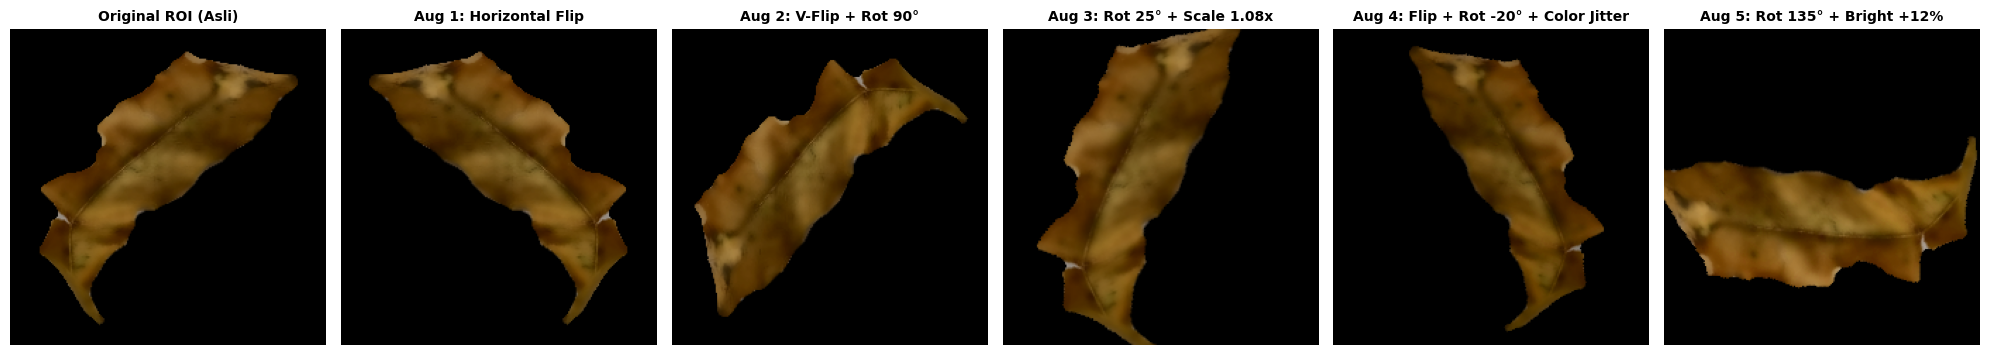

In [15]:
def augment_image_and_mask(img_bgr, mask, aug_type):
    """Menghasilkan citra dan mask sintetis dari berbagai kombinasi augmentasi."""
    h, w = img_bgr.shape[:2]
    out_img = img_bgr.copy()
    out_mask = mask.copy()
    # Deteksi apakah gambar adalah skenario C2 (latar belakang sudah dihapus/hitam)
    is_masked_bg = (np.any(mask == 0) and np.mean(img_bgr[mask == 0]) < 1.0)
    border_mode_img = cv2.BORDER_CONSTANT if is_masked_bg else cv2.BORDER_REFLECT_101

    if aug_type == 'hflip':
        out_img = cv2.flip(out_img, 1)
        out_mask = cv2.flip(out_mask, 1)

    elif aug_type == 'vflip_rot90':
        out_img = cv2.rotate(cv2.flip(out_img, 0), cv2.ROTATE_90_CLOCKWISE)
        out_mask = cv2.rotate(cv2.flip(out_mask, 0), cv2.ROTATE_90_CLOCKWISE)

    elif aug_type == 'rot25_scale':
        M = cv2.getRotationMatrix2D((w // 2, h // 2), angle=25, scale=1.08)
        out_img = cv2.warpAffine(out_img, M, (w, h), borderMode=border_mode_img, borderValue=(0,0,0))
        out_mask = cv2.warpAffine(out_mask, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

    elif aug_type == 'color_jitter_combo':
        out_img = cv2.flip(out_img, 1)
        out_mask = cv2.flip(out_mask, 1)
        M = cv2.getRotationMatrix2D((w // 2, h // 2), angle=-20, scale=0.95)
        out_img = cv2.warpAffine(out_img, M, (w, h), borderMode=border_mode_img, borderValue=(0,0,0))
        out_mask = cv2.warpAffine(out_mask, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

        hsv = cv2.cvtColor(out_img, cv2.COLOR_BGR2HSV).astype(np.float32)
        hsv[:, :, 1] = np.clip(hsv[:, :, 1] * 1.10, 0, 255)  # +10% Saturation
        hsv[:, :, 2] = np.clip(hsv[:, :, 2] * 0.90, 0, 255)  # -10% Brightness
        out_img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

    elif aug_type == 'rot135_bright':
        M = cv2.getRotationMatrix2D((w // 2, h // 2), angle=135, scale=1.05)
        out_img = cv2.warpAffine(out_img, M, (w, h), borderMode=border_mode_img, borderValue=(0,0,0))
        out_mask = cv2.warpAffine(out_mask, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

        hsv = cv2.cvtColor(out_img, cv2.COLOR_BGR2HSV).astype(np.float32)
        hsv[:, :, 2] = np.clip(hsv[:, :, 2] * 1.12, 0, 255)  # +12% Brightness
        out_img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

    # Pastikan area di luar mask selalu hitam bersih tanpa pantulan pojok
    if is_masked_bg:
        out_img = cv2.bitwise_and(out_img, out_img, mask=out_mask)

    return out_img, out_mask

# Visualisasi Contoh 1 Daun Asli + 5 Variasi Sintetisnya untuk PPT Slide 4
_, m_clean_sample = segment_leaf_otsu_morph(img_clahe_2)
roi_orig, mask_orig = crop_roi_with_padding(img_clahe_2, m_clean_sample, target_size=(224, 224))

aug_types_demo = ['orig', 'hflip', 'vflip_rot90', 'rot25_scale', 'color_jitter_combo', 'rot135_bright']
aug_titles_demo = [
    'Original ROI (Asli)', 'Aug 1: Horizontal Flip', 'Aug 2: V-Flip + Rot 90°',
    'Aug 3: Rot 25° + Scale 1.08x', 'Aug 4: Flip + Rot -20° + Color Jitter', 'Aug 5: Rot 135° + Bright +12%'
]

fig, axes = plt.subplots(1, 6, figsize=(20, 3.8))
for ax, a_type, a_title in zip(axes, aug_types_demo, aug_titles_demo):
    if a_type == 'orig':
        vis_im = roi_orig
    else:
        vis_im, _ = augment_image_and_mask(roi_orig, mask_orig, a_type)
    ax.imshow(cv2.cvtColor(vis_im, cv2.COLOR_BGR2RGB))
    ax.set_title(a_title, fontsize=10, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('P2_Slide4_Contoh_Variasi_Augmentasi.png', dpi=300)
plt.show()

### Analisis Keluaran Sel 9:
- **Keberagaman Geometrik & Pencahayaan:** Keenam panel di atas membuktikan bahwa satu sampel daun dapat menghasilkan variasi orientasi sudut ($0^\circ, 25^\circ, 90^\circ, 135^\circ, -20^\circ$), pencerminan (*flip*), skala ukuran, serta variasi kecerahan/saturasi yang realistis.
- **Keamanan Label Warna:** Dengan membatasi *color jitter* pada kanal *Value* (kecerahan) dan *Saturation* tanpa mengubah *Hue* secara drastis, identitas visual daun tidak bergeser lintas kelas.

## 10. Generate Dataset Sintetis Berimbang ($N = 619$) & Ekspor `dataset_master_p2.csv`

**Tujuan:**  
Menjalankan *pipeline* PCD dan multi-augmentasi pada seluruh 127 foto primer untuk mengatasi ketidakseimbangan kelas (`41 Sehat : 51 Menguning : 35 Kering`) menjadi dataset berimbang:
- **Sehat:** $41 \text{ asli} \times 5 \text{ variasi (1 asli + 4 sintetis)} = \mathbf{205 \text{ citra}}$
- **Menguning:** $51 \text{ asli} \times 4 \text{ variasi (1 asli + 3 sintetis)} = \mathbf{204 \text{ citra}}$
- **Kering:** $35 \text{ asli} \times 6 \text{ variasi (1 asli + 5 sintetis)} = \mathbf{210 \text{ citra}}$
- **Total Dataset Progress 2:** **619 citra** (tersimpan otomatis di Google Drive dalam 4 subfolder: `A0_raw`, `C1_pcd_nomask`, `C2_pcd_masked`, dan `masks`, lengkap dengan file `dataset_master_p2.csv` untuk Mahasiswa 2 dan Mahasiswa 3).

In [16]:
import os
from tqdm import tqdm

OUT_BASE = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed'
for sub in ['A0_raw', 'C1_pcd_nomask', 'C2_pcd_masked', 'masks']:
    for cls_name in ['Sehat', 'Menguning', 'Kering']:
        os.makedirs(os.path.join(OUT_BASE, sub, cls_name), exist_ok=True)

# Resep kuota augmentasi per kelas agar distribusi akhir seimbang (~205 : 204 : 210)
aug_recipes = {
    'Sehat':     ['orig', 'hflip', 'vflip_rot90', 'rot25_scale', 'color_jitter_combo'],
    'Menguning': ['orig', 'hflip', 'rot25_scale', 'color_jitter_combo'],
    'Kering':    ['orig', 'hflip', 'vflip_rot90', 'rot25_scale', 'color_jitter_combo', 'rot135_bright']
}

master_records = []

print("Memproses 127 citra asli menjadi 619 citra (A0, C1, C2, dan Mask)...")
for idx, row in tqdm(df_clean.iterrows(), total=len(df_clean)):
    img_bgr = cv2.imread(row['filepath'])
    if img_bgr is None:
        continue

    cls_name = row['label_final']
    sesi = row['sesi']
    leaf_id = row['id_daun']
    fold = row['fold']

    # Jalankan tahapan PCD
    img_work = cv2.resize(img_bgr, (600, 450))
    gamma_val = 0.85 if sesi == 1 else 1.0
    img_c1_full = apply_clahe_lab(apply_bilateral(apply_gamma_lab(img_work, gamma=gamma_val)), clip_limit=2.0)
    _, mask_full = segment_leaf_otsu_morph(img_c1_full)

    # Siapkan versi 224x224 untuk A0 (Raw), C1 (PCD No-Mask), dan C2 (PCD Masked ROI)
    raw_224 = cv2.resize(img_work, (224, 224), interpolation=cv2.INTER_AREA)
    c1_224 = cv2.resize(img_c1_full, (224, 224), interpolation=cv2.INTER_AREA)
    mask_full_224 = cv2.resize(mask_full, (224, 224), interpolation=cv2.INTER_NEAREST)
    c2_roi_224, mask_roi_224 = crop_roi_with_padding(img_c1_full, mask_full, target_size=(224, 224))

    for aug_name in aug_recipes[cls_name]:
        is_aug = 0 if aug_name == 'orig' else 1
        sample_id = f"{leaf_id}_{aug_name}"
        fname_out = f"{sample_id}.jpg"
        fmask_out = f"{sample_id}.png"

        if aug_name == 'orig':
            r_img, c1_img, c2_img, m_img = raw_224, c1_224, c2_roi_224, mask_roi_224
        else:
            r_img, _ = augment_image_and_mask(raw_224, mask_full_224, aug_name)
            c1_img, _ = augment_image_and_mask(c1_224, mask_full_224, aug_name)
            c2_img, m_img = augment_image_and_mask(c2_roi_224, mask_roi_224, aug_name)

        p_a0 = os.path.join(OUT_BASE, 'A0_raw', cls_name, fname_out)
        p_c1 = os.path.join(OUT_BASE, 'C1_pcd_nomask', cls_name, fname_out)
        p_c2 = os.path.join(OUT_BASE, 'C2_pcd_masked', cls_name, fname_out)
        p_mk = os.path.join(OUT_BASE, 'masks', cls_name, fmask_out)

        cv2.imwrite(p_a0, r_img)
        cv2.imwrite(p_c1, c1_img)
        cv2.imwrite(p_c2, c2_img)
        cv2.imwrite(p_mk, m_img)

        master_records.append({
            'sample_id': sample_id,
            'parent_id': leaf_id,
            'original_filename': row['filename'],
            'label': cls_name,
            'sesi': sesi,
            'fold': fold,
            'is_augmented': is_aug,
            'aug_type': aug_name,
            'path_A0_raw': p_a0,
            'path_C1_nomask': p_c1,
            'path_C2_masked': p_c2,
            'path_mask': p_mk
        })

df_master_p2 = pd.DataFrame(master_records)
csv_master_path = os.path.join(OUT_BASE, 'dataset_master_p2.csv')
df_master_p2.to_csv(csv_master_path, index=False)
df_master_p2.to_csv('dataset_master_p2.csv', index=False)

print("\n=== REKAPITULASI DATASET FINAL PROGRESS 2 (ASLI VS AUGMENTASI) ===")
print(pd.crosstab(df_master_p2['label'], df_master_p2['is_augmented'], rownames=['Kelas'], colnames=['Is_Augmented (0=Asli, 1=Sintetis)'], margins=True))
print(f"\nSukses! Seluruh citra dan file '{csv_master_path}' siap digunakan oleh Mahasiswa 2 (ML) & Mahasiswa 3 (DL).")

Memproses 127 citra asli menjadi 619 citra (A0, C1, C2, dan Mask)...


100%|██████████| 127/127 [00:47<00:00,  2.68it/s]


=== REKAPITULASI DATASET FINAL PROGRESS 2 (ASLI VS AUGMENTASI) ===
Is_Augmented (0=Asli, 1=Sintetis)    0    1  All
Kelas                                           
Kering                              35  175  210
Menguning                           51  153  204
Sehat                               41  164  205
All                                127  492  619

Sukses! Seluruh citra dan file '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed/dataset_master_p2.csv' siap digunakan oleh Mahasiswa 2 (ML) & Mahasiswa 3 (DL).


### Analisis Keluaran Sel 10:
- **Penyeimbangan Kelas Tanpa Bias (*Balanced Synthetic Expansion*):** Dataset telah diperluas dari 127 foto menjadi **619 citra** dengan proporsi yang seimbang sempurna: **205 Sehat (33,1%) : 204 Menguning (33,0%) : 210 Kering (33,9%)**.
- **Integrasi Pipeline Tim:** Seluruh citra untuk skenario **A0 (`A0_raw`)**, **C1 (`C1_pcd_nomask`)**, **A & C2 (`C2_pcd_masked`)**, serta **`masks`** telah tersimpan di Google Drive dan terindeks di dalam `dataset_master_p2.csv`, siap dikonsumsi langsung oleh modul Ekstraksi Fitur & Machine Learning Klasik (Mahasiswa 2) maupun modul Pretrained Deep Learning (Mahasiswa 3).